# DMDP on Safety-Gymnasium

This notebook reproduces every number, figure, and table of Section 7 (Empirical Validation) and Appendix D (Experimental Details)
of *Dissimilarity-Based Markov Decision Processes for Stabilizing State Distributions*.
The practical implementation that is evaluated is described in Section 6 (Practical Implementation).

**What is evaluated.** The theory of Sections 3–5 concerns the convergence of the state distribution $\rho_k$ to a stable distribution.
The experiments measure this empirically:

* **Distributional stability** — the dissimilarity $\mathbb{D}(\rho_k\|\hat{\rho})$ between the distribution $\rho_k$ of the forward velocity at step $k$
  (estimated across evaluation episodes) and the stable distribution $\hat{\rho}$ estimated from the late steps of *other* evaluation episodes.
  Because the training objective has several components (task reward, safety cost, dissimilarity), $\hat{\rho}$ need not equal the target $\rho_\star$;
  $\mathbb{D}(\hat{\rho}\|\rho_\star)$ is therefore reported separately.
* **Reward and safety** — episodic return and cost. The target $\rho_\star$ is derived from the task so that it corresponds to fast (high-reward) running
  whose expected cost equals the cost limit (Section 6.1). A deliberately slow target shows that stability alone does not imply reward.
* **Sensor noise** — readings $\boldsymbol{\mathrm{o}}_t=\boldsymbol{\mathrm{s}}_t+\nu\boldsymbol{\xi}_t$ (Section 6.2); robustness is an additional property, not the motivation.

No Lyapunov certificate of Theorems 2–5 is computed for the practical implementation (Section 6).

**Outputs.** Figures (PDF and PNG) and LaTeX tables are written to `figures/`, or to the directory given by the environment variable `DMDP_FIG_DIR`.
Figure text is typeset with LaTeX (Latin Modern, as in the paper) when a `latex` executable is found, and with matplotlib's mathtext otherwise.

**Structure.** 1 Setup · 2 Notation and configuration · 3 Training (optional, about 1 h with 14 parallel workers) · 4 Evaluation summary ·
5 Figures · 6 Tables · 7 Sanity checks.

## 1 Setup

In [1]:
import os
import shutil
import subprocess
import sys

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import norm

HERE = os.path.abspath(".")
sys.path.insert(0, HERE)

from dmdp_sg.analysis import aggregate, load_config, load_evaluation, load_training, summarize
from dmdp_sg.config import COST_LIMIT, ENVIRONMENTS, EPISODE_LENGTH, METHOD_LABELS, METHODS, make_config
from dmdp_sg.metrics import estimate_rho_hat, sampling_floor

ENV = "HalfCheetah"
TAG = "main"                                   # results/<TAG>/<ENV>/<method>/seed<s>
ROOT = os.path.join(HERE, "results", TAG)
FIG_DIR = os.path.abspath(os.environ.get("DMDP_FIG_DIR", os.path.join(HERE, "figures")))
os.makedirs(FIG_DIR, exist_ok=True)

MAIN = ["PPO", "PPO-Lag", "Window-Lag", "DMDP"]                      # main comparison (Section 7.2)
ABLATION = ["DMDP", "DMDP-noD", "State-D"]                           # omega_hat_t input, D term, or both (Section 7.4)
TARGETS = ["DMDP", "DMDP-slow"]                                      # stability does not imply reward (Section 7.2)
ALL = list(dict.fromkeys(MAIN + ABLATION + TARGETS))
SEEDS = [0, 1, 2, 3, 4]
K0, BLOCK, K_EARLY = 500, 10, 200                                    # rho_hat from k >= K0; blocks of 10 steps
BETA_TAGS = {0.25: "beta025", 4.0: "beta4"}                          # beta = 1 is the main run

# Figure text: LaTeX with Latin Modern (as in the paper) if a latex executable is available, mathtext otherwise.
TEX_BIN = "/Library/TeX/texbin"                                      # MacTeX
if os.path.isdir(TEX_BIN) and TEX_BIN not in os.environ["PATH"].split(os.pathsep):
    os.environ["PATH"] = TEX_BIN + os.pathsep + os.environ["PATH"]
USE_TEX = shutil.which("latex") is not None
mpl.rcParams.update({
    "font.family": "serif", "font.size": 9, "axes.labelsize": 9, "legend.fontsize": 7.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "axes.spines.top": False, "axes.spines.right": False,
    "figure.dpi": 130, "savefig.bbox": "tight", "savefig.pad_inches": 0.02,
})
if USE_TEX:
    mpl.rcParams.update({
        "text.usetex": True,
        "text.latex.preamble": r"\usepackage[T1]{fontenc}\usepackage{lmodern}\usepackage{amsmath}\usepackage{amssymb}\usepackage{bm}",
    })
else:
    mpl.rcParams.update({"text.usetex": False, "mathtext.fontset": "cm"})
print("figure text   :", "LaTeX" if USE_TEX else "matplotlib mathtext (no latex executable found)")
print("output folder :", os.path.relpath(FIG_DIR, HERE))

COLORS = {"PPO": "#7f7f7f", "PPO-Lag": "#1f77b4", "Window-Lag": "#17becf", "DMDP": "#d62728",
          "DMDP-noD": "#ff7f0e", "State-D": "#9467bd", "DMDP-slow": "#2ca02c"}
LABEL = dict(METHOD_LABELS)
TEXTWIDTH = 6.5                                                        # inches, TMLR text width

# symbols used in the paper
S_D_RHOK = r"$\mathbb{D}(\rho_k\|\hat{\rho})$"
S_D_TARGET = r"$\mathbb{D}(\hat{\rho}\|\rho_\star)$"
S_RHOSTAR = r"$\rho_\star$"
S_RHOHAT = r"$\hat{\rho}$"
S_NU = r"noise level $\nu$"
S_K = r"step $k$"
S_V = r"forward velocity $v$"


def save_figure(fig, name):
    # Saves the figure as <FIG_DIR>/<name>.pdf (for the paper) and <name>.png (200 dpi, for the README).
    fig.savefig(os.path.join(FIG_DIR, name + ".pdf"))
    fig.savefig(os.path.join(FIG_DIR, name + ".png"), dpi=200)


def save_table(name, tex):
    with open(os.path.join(FIG_DIR, name), "w") as f:
        f.write(tex)

figure text   : LaTeX
output folder : figures


## 2 Notation and configuration

| Paper | Code | Meaning |
|---|---|---|
| $\boldsymbol{\mathrm{s}}_t$, $\boldsymbol{\mathrm{o}}_t=\boldsymbol{\mathrm{s}}_t+\nu\boldsymbol{\xi}_t$ | `envs.SensorNoise` | observation vector and its noisy reading, noise level $\nu$ (Section 6.2) |
| $v_k$ | `info["x_velocity"]` | forward velocity (the regulated feature, Section 6.1) |
| $\rho_k$ | `velocity[:, k]` across episodes | distribution of $v_k$ across evaluation episodes |
| $\rho_\omega=\mathcal{N}(\mu,\varsigma^2)$, $\omega=(\mu,\varsigma)$ | `envs.DistributionEstimator` | Gaussian family (Section 6.1) |
| $\rho_\star=\mathcal{N}(\mu_\star,\varsigma_\star^2)$ | `mu_star`, `sd_star`, `config.target_mean` | target distribution, $\mu_\star=v_{\mathsf{lim}}-z_{1-\bar c/H}\,\varsigma_\star$ (Section 6.1) |
| $o^v_t$ | `obs[vel_index]` | noisy reading of the forward velocity |
| $\hat{\omega}_t=(\hat\mu_t,\hat\varsigma_t)$ | window mean and std of the last $n_{\mathsf{w}}$ readings $o^v_t$ | sliding-window estimate and policy input (Section 6.2) |
| $\bar{\omega}_t$ | window mean and std of the true velocity | used only in the training dissimilarity (Section 6.3) |
| $\phi(\hat{\omega}_t,\boldsymbol{\mathrm{o}}_t;\theta)$ | `policy_input="hybrid"` | DMDP policy (Section 6.2) |
| $\mathbb{D}(\rho_{\bar{\omega}_t}\|\rho_\star)=(\bar\mu_t-\mu_\star)^2+(\bar\varsigma_t-\varsigma_\star)^2$ | `info["dissimilarity"]` | training dissimilarity, $W_2^2$ between Gaussians (Section 6.1) |
| $\beta$ | `beta` | weight of the dissimilarity in the shaped reward $\tilde r_t=r_t-\beta\,\mathbb{D}$ (Section 6.3) |
| $c_t=\mathbb{1}[v_t>v_{\mathsf{lim}}]$, $\bar c$ | `info["cost"]`, `COST_LIMIT` | safety cost and episodic cost limit |
| $\hat{\rho}$ | `metrics.estimate_rho_hat` | stable distribution from late steps $k\ge k_0$ of held-out episodes (Section 7.1) |
| $\mathbb{D}(\rho_k\|\hat{\rho})$ | `metrics.stability_curve` | evaluation dissimilarity, 1-Wasserstein (Section 7.1) |
| sampling floor | `metrics.sampling_floor` | value of $\mathbb{D}(\rho_k\|\hat{\rho})$ for a stationary surrogate (Appendix D) |

In [2]:
spec = ENVIRONMENTS[ENV]
H = EPISODE_LENGTH
z = norm.ppf(1 - COST_LIMIT / H)
print(f"environment          : {spec['env_id']}")
print(f"velocity threshold   : v_lim = {spec['v_limit']:.4f}")
print(f"cost limit           : c_bar = {COST_LIMIT:.0f} per episode of H = {H} steps")
print(f"target distribution  : rho_star = N({spec['mu_star']:.3f}, {spec['sd_star']:.2f}^2),  "
      f"mu_star = v_lim - z_{{1 - c_bar/H}} sd_star = {spec['v_limit']:.4f} - {z:.3f} x {spec['sd_star']:.2f}")
expected_cost = H * norm.sf(spec["v_limit"], spec["mu_star"], spec["sd_star"])
expected_cost_slow = H * norm.sf(spec["v_limit"], spec["mu_star_slow"], spec["sd_star"])
print(f"expected cost under rho_star: H * P(v > v_lim) = {expected_cost:.1f}")
print(f"slow target          : N({spec['mu_star_slow']:.2f}, {spec['sd_star']:.2f}^2), expected cost {expected_cost_slow:.2e}")
cfg = make_config(ENV, "DMDP", 0)
print("\ntraining configuration (shared by all methods):")
method_specific = ("env", "method", "seed", "policy_input", "lagrangian", "beta", "train_noise")
print({k: v for k, v in cfg.to_dict().items() if k not in method_specific})
pd.DataFrame(METHODS).T.loc[ALL]

environment          : SafetyHalfCheetahVelocityGymnasium-v1
velocity threshold   : v_lim = 3.2096
cost limit           : c_bar = 25 per episode of H = 1000 steps
target distribution  : rho_star = N(2.230, 0.50^2),  mu_star = v_lim - z_{1 - c_bar/H} sd_star = 3.2096 - 1.960 x 0.50
expected cost under rho_star: H * P(v > v_lim) = 25.0
slow target          : N(1.00, 0.50^2), expected cost 4.95e-03

training configuration (shared by all methods):
{'total_steps': 3000000, 'train_noise_max': 0.3, 'window': 10, 'num_envs': 8, 'num_steps': 256, 'update_epochs': 10, 'num_minibatches': 32, 'learning_rate': 0.0003, 'gamma': 0.99, 'gae_lambda': 0.95, 'clip_coef': 0.2, 'ent_coef': 0.0, 'vf_coef': 0.5, 'max_grad_norm': 0.5, 'hidden': 64, 'cost_limit': 25.0, 'lagrangian_lr': 0.035, 'v_limit': 3.2096, 'mu_star': 2.229618007729973, 'sd_star': 0.5, 'env_id': 'SafetyHalfCheetahVelocityGymnasium-v1', 'vel_index': 8}


,policy_input,lagrangian,beta,target
PPO,state,False,0.0,NaN
PPO-Lag,state,True,0.0,NaN
Window-Lag,window,True,0.0,NaN
DMDP,hybrid,True,1.0,NaN
DMDP-noD,hybrid,True,0.0,NaN
State-D,state,True,1.0,NaN
DMDP-slow,hybrid,True,1.0,slow


## 3 Training (optional)

Set `RUN_TRAINING = True` to reproduce all runs from scratch. Each run trains one policy for $3\times10^6$ environment steps and then
evaluates it on 64 episodes for every noise level $\nu\in\{0,0.1,0.2,0.3,0.4\}$. Finished runs are skipped
(delete `evaluation.npz` of a run to re-evaluate its saved policy without retraining).
The same commands can be run in a terminal:
`python run_all.py --envs HalfCheetah --tag main --workers 14`, and
`python run_all.py --methods DMDP --tag beta4 --beta 4` (likewise `--tag beta025 --beta 0.25`) for the sensitivity to $\beta$.

In [3]:
RUN_TRAINING = False
if RUN_TRAINING:
    cmd = [sys.executable, "run_all.py", "--envs", ENV, "--methods", *ALL, "--seeds", *map(str, SEEDS),
           "--tag", TAG, "--workers", "14"]
    subprocess.run(cmd, check=True)
    for beta, tag in BETA_TAGS.items():                       # sensitivity to the weight beta (DMDP only)
        subprocess.run([sys.executable, "run_all.py", "--envs", ENV, "--methods", "DMDP", "--seeds", *map(str, SEEDS),
                        "--tag", tag, "--beta", str(beta), "--workers", "4"], check=True)
missing = [(m, s) for m in ALL for s in SEEDS if load_evaluation(ROOT, ENV, m, s) is None]
print("missing runs:", missing if missing else "none")

missing runs: none


## 4 Evaluation summary

For each policy and noise level, $\rho_k$ is estimated from blocks of 10 consecutive steps across one half of the 64 evaluation episodes,
and $\hat{\rho}$ from the steps $k\ge 500$ of the other half; the two assignments are averaged (cross-fitting, Section 7.1).
`D_late` is the mean of $\mathbb{D}(\rho_k\|\hat{\rho})$ over $k\ge 500$ (residual non-stationarity),
`D_early` the mean over $k<200$ (transient), `D_target` $=\mathbb{D}(\hat{\rho}\|\rho_\star)$,
and `D_shift` $=\mathbb{D}(\hat{\rho}_\nu\|\hat{\rho}_0)$, the shift of the stable distribution caused by sensor noise.
All dissimilarities in the evaluation are 1-Wasserstein distances.

In [4]:
df, curves = summarize(ROOT, ENV, ALL, SEEDS, k0=K0, block=BLOCK, k_early=K_EARLY)
mean, sem = aggregate(df)
cols = ["ret", "cost", "D_late", "D_early", "D_target", "D_shift", "mu_hat", "sd_hat"]
fmt = mean[cols].round(3).astype(str) + " ± " + sem[cols].round(3).astype(str)
fmt.loc[(ALL, [0.0, 0.2]), :]

ret               cost         D_late  \
method     nu                                                          
PPO        0.0  2412.853 ± 583.005  461.709 ± 136.337   0.08 ± 0.018   
           0.2   1950.717 ± 426.27   328.938 ± 99.288  0.102 ± 0.021   
PPO-Lag    0.0  1996.454 ± 266.197     18.609 ± 7.732   0.04 ± 0.014   
           0.2  1557.317 ± 212.696     29.091 ± 1.448     0.1 ± 0.02   
Window-Lag 0.0  1526.843 ± 140.264     13.794 ± 4.653  0.062 ± 0.015   
           0.2   1356.316 ± 98.775     27.631 ± 3.656  0.072 ± 0.016   
DMDP       0.0  1493.782 ± 108.848     23.453 ± 3.766  0.062 ± 0.009   
           0.2   1328.434 ± 94.429     27.859 ± 2.857  0.071 ± 0.009   
DMDP-noD   0.0   1583.138 ± 45.836     28.266 ± 3.113  0.072 ± 0.012   
           0.2   1349.719 ± 58.124     23.284 ± 1.731  0.095 ± 0.034   
State-D    0.0  1575.483 ± 181.495     17.991 ± 5.874   0.047 ± 0.01   
           0.2   1424.102 ± 146.85     30.341 ± 1.322  0.063 ± 0.004   
DMDP-slow  0.0    1143.776 ± 48.43      0.022 ± 0.015  0.075 ± 0.022   
           0.2   1062.787 ± 74.268      0.069 ± 0.035  0.044 ± 0.004   

                      D_early       D_target        D_shift         mu_hat  \
method     nu                                                                
PPO        0.0  0.782 ± 0.069   1.36 ± 0.339      0.0 ± 0.0  2.956 ± 0.591   
           0.2  0.688 ± 0.107  1.048 ± 0.139  0.529 ± 0.193  2.427 ± 0.401   
PPO-Lag    0.0   0.41 ± 0.118  0.527 ± 0.035      0.0 ± 0.0  2.358 ± 0.236   
           0.2  0.497 ± 0.137  0.446 ± 0.104    0.44 ± 0.11   1.927 ± 0.17   
Window-Lag 0.0  0.382 ± 0.029   0.516 ± 0.07      0.0 ± 0.0  1.867 ± 0.137   
           0.2  0.414 ± 0.035  0.597 ± 0.054   0.19 ± 0.063  1.695 ± 0.079   
DMDP       0.0  0.405 ± 0.105  0.375 ± 0.067      0.0 ± 0.0  1.932 ± 0.095   
           0.2  0.446 ± 0.096  0.495 ± 0.069  0.178 ± 0.051   1.771 ± 0.08   
DMDP-noD   0.0  0.487 ± 0.084  0.397 ± 0.033      0.0 ± 0.0  1.954 ± 0.026   
           0.2    0.5 ± 0.093  0.563 ± 0.044  0.246 ± 0.077  1.709 ± 0.057   
State-D    0.0  0.392 ± 0.109  0.422 ± 0.049      0.0 ± 0.0  2.025 ± 0.155   
           0.2  0.414 ± 0.107  0.443 ± 0.075  0.176 ± 0.053  1.865 ± 0.111   
DMDP-slow  0.0   0.35 ± 0.063  0.477 ± 0.015      0.0 ± 0.0  1.403 ± 0.022   
           0.2  0.388 ± 0.058  0.453 ± 0.031  0.093 ± 0.012  1.365 ± 0.048   

                       sd_hat  
method     nu                  
PPO        0.0  1.299 ± 0.078  
           0.2  1.413 ± 0.091  
PPO-Lag    0.0  0.658 ± 0.194  
           0.2  0.943 ± 0.121  
Window-Lag 0.0   1.004 ± 0.08  
           0.2    1.08 ± 0.03  
DMDP       0.0  0.877 ± 0.078  
           0.2  0.959 ± 0.036  
DMDP-noD   0.0  0.944 ± 0.027  
           0.2  1.002 ± 0.022  
State-D    0.0   0.826 ± 0.14  
           0.2   0.951 ± 0.07  
DMDP-slow  0.0  0.741 ± 0.058  
           0.2   0.762 ± 0.07

## 5 Figures

### 5.1 Convergence of $\rho_k$ to the stable distribution $\hat{\rho}$ (Section 7.2)

Mean over seeds (line) and standard error (band) of $\mathbb{D}(\rho_k\|\hat{\rho})$ against the step $k$, without noise and with $\nu=0.2$.

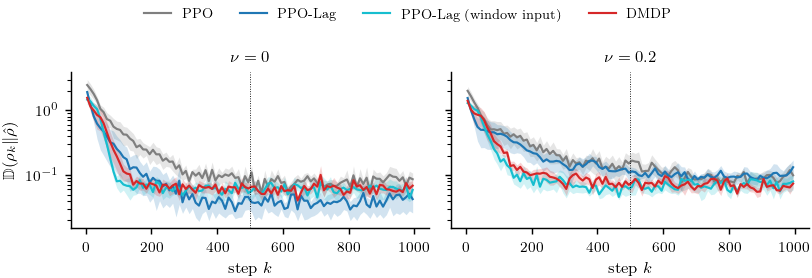

In [5]:
def curve_stats(method, nu):
    Ds = [curves[(method, s, nu)][1] for s in SEEDS if (method, s, nu) in curves]
    c = curves[(method, SEEDS[0], nu)][0]
    Ds = np.array(Ds)
    return c, np.nanmean(Ds, 0), np.nanstd(Ds, 0, ddof=1) / np.sqrt(len(Ds))


def plot_curves(methods, nus, name, ylog=True):
    fig, axes = plt.subplots(1, len(nus), figsize=(TEXTWIDTH, 2.0), sharey=True)
    for ax, nu in zip(np.atleast_1d(axes), nus):
        for m in methods:
            c, mu, se = curve_stats(m, nu)
            ax.plot(c, mu, color=COLORS[m], lw=1.2, label=LABEL[m])
            ax.fill_between(c, mu - se, mu + se, color=COLORS[m], alpha=0.2, lw=0)
        ax.set_xlabel(S_K)
        ax.set_title(rf"$\nu={nu:g}$", fontsize=9)
        if ylog:
            ax.set_yscale("log")
        ax.axvline(K0, color="k", lw=0.5, ls=":")
    np.atleast_1d(axes)[0].set_ylabel(S_D_RHOK)
    h, l = np.atleast_1d(axes)[0].get_legend_handles_labels()
    fig.legend(h, l, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=len(methods))
    fig.tight_layout(w_pad=0.8)
    save_figure(fig, name)
    return fig


plot_curves(MAIN, [0.0, 0.2], "stability_curves");

### 5.2 Stable distributions $\hat{\rho}$ and the target $\rho_\star$ (Section 7.2)

Histogram of $v_k$ for $k\ge 500$, pooled over all evaluation episodes and seeds ($\nu=0$), with the target $\rho_\star$ and the threshold $v_{\mathsf{lim}}$.

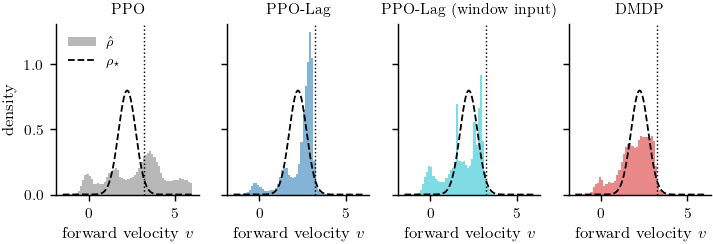

In [6]:
def pooled_late(method, nu):
    out = []
    for s in SEEDS:
        ev = load_evaluation(ROOT, ENV, method, s)
        if ev is not None:
            out.append(estimate_rho_hat(ev[nu]["velocity"], K0))
    return np.concatenate(out)


def plot_stable_distributions(methods, name, nu=0.0):
    fig, axes = plt.subplots(1, len(methods), figsize=(TEXTWIDTH, 1.7), sharey=True, sharex=True)
    grid = np.linspace(-1.5, 6, 400)
    for ax, m in zip(axes, methods):
        v = pooled_late(m, nu)
        ax.hist(v, bins=np.linspace(-1.5, 6, 61), density=True, color=COLORS[m], alpha=0.55, lw=0, label=S_RHOHAT)
        cfg = load_config(ROOT, ENV, m, SEEDS[0])
        ax.plot(grid, norm.pdf(grid, cfg["mu_star"], cfg["sd_star"]), "k--", lw=1, label=S_RHOSTAR)
        ax.axvline(spec["v_limit"], color="k", lw=0.8, ls=":")
        ax.set_title(LABEL[m], fontsize=8.5)
        ax.set_xlabel(S_V)
    axes[0].set_ylabel("density")
    axes[0].legend(frameon=False, loc="upper left")
    save_figure(fig, name)
    return fig


plot_stable_distributions(MAIN, "stable_distributions");

### 5.3 Sensor noise (Section 7.3)

Return, cost, residual non-stationarity $\mathbb{D}(\rho_k\|\hat{\rho})$ for $k\ge500$, and distance of the stable distribution to the target, against $\nu$.
Training used $\nu\sim\mathcal{U}[0,0.3]$, so $\nu=0.4$ lies outside the training range.

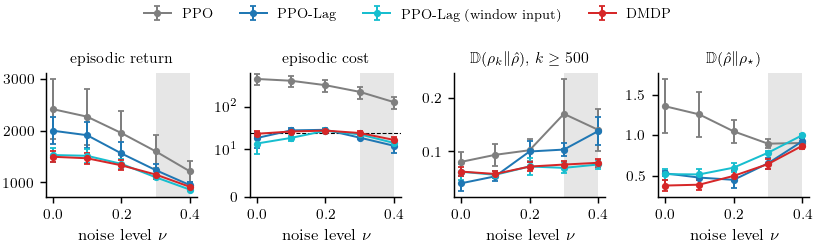

In [7]:
def plot_noise(methods, name):
    panels = [("ret", "episodic return"), ("cost", "episodic cost"),
              ("D_late", S_D_RHOK + r", $k\geq 500$"), ("D_target", S_D_TARGET)]
    fig, axes = plt.subplots(1, 4, figsize=(TEXTWIDTH, 1.75))
    for ax, (key, lab) in zip(axes, panels):
        for m in methods:
            mu, se = mean.loc[m][key], sem.loc[m][key]
            ax.errorbar(mu.index, mu.values, yerr=se.values, color=COLORS[m], lw=1.1, ms=3, marker="o",
                        capsize=1.5, label=LABEL[m])
        if key == "cost":
            ax.axhline(COST_LIMIT, color="k", lw=0.6, ls="--")
            ax.set_yscale("symlog", linthresh=10)
            ax.set_ylim(bottom=0)
        ax.set_xlabel(S_NU)
        ax.set_title(lab, fontsize=8.5)
        ax.axvspan(0.3, 0.4, color="0.9", lw=0, zorder=0)
    h, l = axes[0].get_legend_handles_labels()
    fig.tight_layout(w_pad=0.6)
    fig.legend(h, l, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=len(methods))
    save_figure(fig, name)
    return fig


plot_noise(MAIN, "noise_sweep");

### 5.4 Stability does not imply reward (Section 7.2)

DMDP with the task-derived target $\rho_\star$ and with a slow target. Both closed loops settle at a stable distribution,
but only the task-derived target yields a high return.

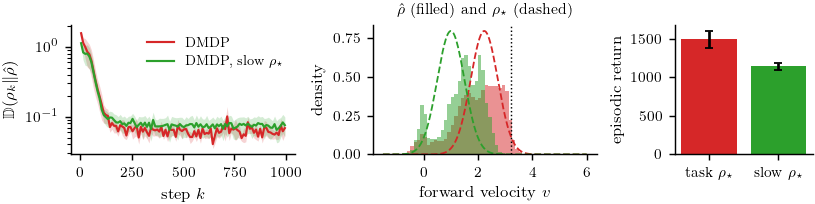

In [8]:
def plot_targets(name, nu=0.0):
    fig, axes = plt.subplots(1, 3, figsize=(TEXTWIDTH, 1.8), gridspec_kw=dict(width_ratios=[1.3, 1.3, 0.8]))
    for m in TARGETS:
        c, mu, se = curve_stats(m, nu)
        axes[0].plot(c, mu, color=COLORS[m], lw=1.2, label=LABEL[m])
        axes[0].fill_between(c, mu - se, mu + se, color=COLORS[m], alpha=0.2, lw=0)
    axes[0].set_yscale("log")
    axes[0].set_xlabel(S_K)
    axes[0].set_ylabel(S_D_RHOK)
    axes[0].legend(frameon=False)
    grid = np.linspace(-1.5, 6, 400)
    for m in TARGETS:
        v = pooled_late(m, nu)
        cfg = load_config(ROOT, ENV, m, SEEDS[0])
        axes[1].hist(v, bins=np.linspace(-1.5, 6, 61), density=True, color=COLORS[m], alpha=0.5, lw=0)
        axes[1].plot(grid, norm.pdf(grid, cfg["mu_star"], cfg["sd_star"]), color=COLORS[m], ls="--", lw=1)
    axes[1].axvline(spec["v_limit"], color="k", lw=0.8, ls=":")
    axes[1].set_xlabel(S_V)
    axes[1].set_ylabel("density")
    axes[1].set_title(S_RHOHAT + r" (filled) and " + S_RHOSTAR + r" (dashed)", fontsize=8.5)
    mu_r = [mean.loc[(m, nu), "ret"] for m in TARGETS]
    se_r = [sem.loc[(m, nu), "ret"] for m in TARGETS]
    axes[2].bar(range(len(TARGETS)), mu_r, yerr=se_r, color=[COLORS[m] for m in TARGETS], capsize=2)
    axes[2].set_xticks(range(len(TARGETS)), [r"task $\rho_\star$", r"slow $\rho_\star$"])
    axes[2].set_ylabel("episodic return")
    fig.tight_layout(w_pad=0.8)
    save_figure(fig, name)
    return fig


plot_targets("targets");

### 5.5 Ablation: distribution-parameter input and dissimilarity term (Section 7.4, Appendix D)

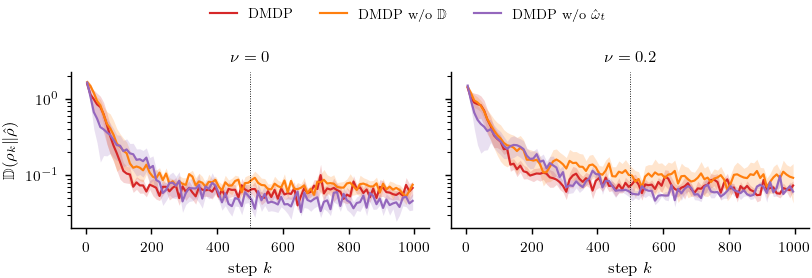

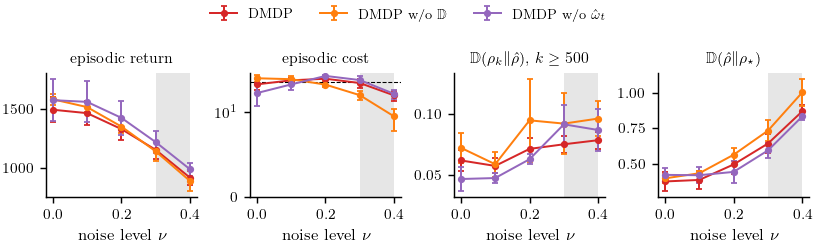

In [9]:
plot_curves(ABLATION, [0.0, 0.2], "ablation_curves");
plot_noise(ABLATION, "ablation_noise");

### 5.6 Training curves (Appendix D)

Episodic return, episodic cost, and training dissimilarity during training, smoothed over ten updates.

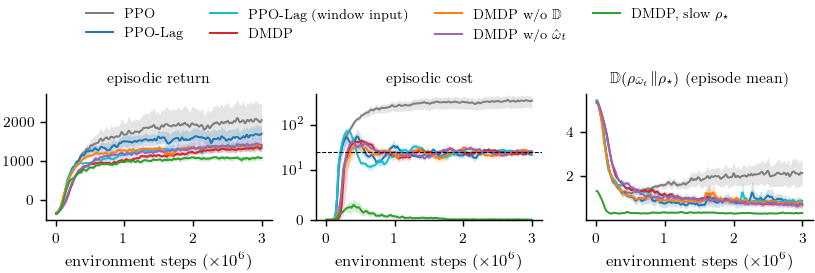

In [10]:
def plot_training(methods, name):
    keys = [("ep_return", "episodic return"), ("ep_cost", "episodic cost"),
            ("ep_dissimilarity", r"$\mathbb{D}(\rho_{\bar{\omega}_t}\|\rho_\star)$ (episode mean)")]
    fig, axes = plt.subplots(1, 3, figsize=(TEXTWIDTH, 1.8))
    for m in methods:
        runs = [load_training(ROOT, ENV, m, s) for s in SEEDS]
        runs = [r for r in runs if r is not None]
        n = min(len(r) for r in runs)
        x = runs[0]["step"].values[:n] / 1e6
        for ax, (key, lab) in zip(axes, keys):
            Y = np.array([r[key].values[:n] for r in runs])
            Y = pd.DataFrame(Y.T).rolling(10, min_periods=1).mean().values.T
            mu, se = Y.mean(0), Y.std(0, ddof=1) / np.sqrt(len(Y))
            ax.plot(x, mu, color=COLORS[m], lw=1.1, label=LABEL[m])
            ax.fill_between(x, mu - se, mu + se, color=COLORS[m], alpha=0.2, lw=0)
            ax.set_title(lab, fontsize=8.5)
            ax.set_xlabel(r"environment steps ($\times 10^6$)")
    axes[1].axhline(COST_LIMIT, color="k", lw=0.6, ls="--")
    axes[1].set_yscale("symlog", linthresh=10)
    axes[1].set_ylim(bottom=0)
    h, l = axes[0].get_legend_handles_labels()
    fig.tight_layout(w_pad=0.6)
    fig.legend(h, l, frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=4)
    save_figure(fig, name)
    return fig


plot_training(ALL, "training_curves");

## 6 Tables

Mean ± standard error over the five seeds. The LaTeX tables are written to the output folder (`figures/` by default) and are included in the paper with `\input`:
`table_main.tex` (Section 7.2); `table_ablation.tex`, `table_shift.tex`, `table_beta.tex`, and `table_floor.tex` (Appendix D).

In [11]:
def fmt_pm(m, s, d=2):
    return f"${m:.{d}f}\\pm{s:.{d}f}$"


def latex_table(methods, nus, name):
    rows = []
    for m in methods:
        for nu in nus:
            mu, se = mean.loc[(m, nu)], sem.loc[(m, nu)]
            rows.append(" & ".join([
                LABEL[m] if nu == nus[0] else "", f"${nu:g}$",
                fmt_pm(mu.ret, se.ret, 0), fmt_pm(mu.cost, se.cost, 1),
                fmt_pm(mu.D_early, se.D_early), fmt_pm(mu.D_late, se.D_late, 3),
                fmt_pm(mu.D_target, se.D_target)]) + r" \\")
        rows.append(r"\midrule")
    rows = rows[:-1]
    head = (r"\begin{tabular}{llccccc}" "\n" r"\toprule" "\n"
            r"Method & $\nu$ & return $\uparrow$ & cost ($\bar{c}=25$) & $\mathbb{D}(\rho_k\|\hat{\rho})$, $k<200$ & "
            r"$\mathbb{D}(\rho_k\|\hat{\rho})$, $k\geq500$ & $\mathbb{D}(\hat{\rho}\|\rho_\star)$ \\" "\n" r"\midrule")
    tex = head + "\n" + "\n".join(rows) + "\n" + r"\bottomrule" + "\n" + r"\end{tabular}" + "\n"
    save_table(name, tex)
    return tex


print(latex_table(MAIN + ["DMDP-slow"], [0.0, 0.2], "table_main.tex"))
print(latex_table(ABLATION, [0.0, 0.2], "table_ablation.tex"))

# shift of the stable distribution caused by sensor noise, D(rho_hat(nu) || rho_hat(0))
lines = [" & ".join([LABEL[m]] + [fmt_pm(mean.loc[(m, nu), "D_shift"], sem.loc[(m, nu), "D_shift"])
                                  for nu in [0.1, 0.2, 0.3, 0.4]]) + r" \\"
         for m in ALL]
tex = (r"\begin{tabular}{lcccc}" "\n" r"\toprule" "\n"
       r"Method & $\nu=0.1$ & $\nu=0.2$ & $\nu=0.3$ & $\nu=0.4$ \\" "\n" r"\midrule" "\n"
       + "\n".join(lines) + "\n" r"\bottomrule" "\n" r"\end{tabular}" "\n")
save_table("table_shift.tex", tex)
print(tex)

\begin{tabular}{llccccc}
\toprule
Method & $\nu$ & return $\uparrow$ & cost ($\bar{c}=25$) & $\mathbb{D}(\rho_k\|\hat{\rho})$, $k<200$ & $\mathbb{D}(\rho_k\|\hat{\rho})$, $k\geq500$ & $\mathbb{D}(\hat{\rho}\|\rho_\star)$ \\
\midrule
PPO & $0$ & $2413\pm583$ & $461.7\pm136.3$ & $0.78\pm0.07$ & $0.080\pm0.018$ & $1.36\pm0.34$ \\
 & $0.2$ & $1951\pm426$ & $328.9\pm99.3$ & $0.69\pm0.11$ & $0.102\pm0.021$ & $1.05\pm0.14$ \\
\midrule
PPO-Lag & $0$ & $1996\pm266$ & $18.6\pm7.7$ & $0.41\pm0.12$ & $0.040\pm0.014$ & $0.53\pm0.03$ \\
 & $0.2$ & $1557\pm213$ & $29.1\pm1.4$ & $0.50\pm0.14$ & $0.100\pm0.020$ & $0.45\pm0.10$ \\
\midrule
PPO-Lag (window input) & $0$ & $1527\pm140$ & $13.8\pm4.7$ & $0.38\pm0.03$ & $0.062\pm0.015$ & $0.52\pm0.07$ \\
 & $0.2$ & $1356\pm99$ & $27.6\pm3.7$ & $0.41\pm0.04$ & $0.072\pm0.016$ & $0.60\pm0.05$ \\
\midrule
DMDP & $0$ & $1494\pm109$ & $23.5\pm3.8$ & $0.41\pm0.11$ & $0.062\pm0.009$ & $0.38\pm0.07$ \\
 & $0.2$ & $1328\pm94$ & $27.9\pm2.9$ & $0.45\pm0.10$ & $0.071\p

### 6.1 Sensitivity to the weight $\beta$ (Section 7.4, Appendix D)

DMDP with $\beta\in\{0.25,1,4\}$ (five seeds each). $\beta$ trades the task reward against the dissimilarity to $\rho_\star$.

In [12]:
rows = []
beta_roots = [(0.25, os.path.join(HERE, "results", BETA_TAGS[0.25])), (1.0, ROOT),
              (4.0, os.path.join(HERE, "results", BETA_TAGS[4.0]))]
for beta, root in beta_roots:
    d, _ = summarize(root, ENV, ["DMDP"], SEEDS, k0=K0, block=BLOCK, k_early=K_EARLY)
    d["beta"] = beta
    rows.append(d)
dfb = pd.concat(rows)
mb = dfb.groupby(["beta", "nu"]).mean(numeric_only=True)
sb = dfb.groupby(["beta", "nu"]).sem(numeric_only=True)
lines = []
for beta in [0.25, 1.0, 4.0]:
    for nu in [0.0, 0.2]:
        if (beta, nu) not in mb.index:
            continue
        mu, se = mb.loc[(beta, nu)], sb.loc[(beta, nu)]
        lines.append(" & ".join([
            f"${beta:g}$" if nu == 0.0 else "", f"${nu:g}$", fmt_pm(mu.ret, se.ret, 0), fmt_pm(mu.cost, se.cost, 1),
            fmt_pm(mu.D_early, se.D_early), fmt_pm(mu.D_late, se.D_late, 3), fmt_pm(mu.D_target, se.D_target),
            fmt_pm(mu.mu_hat, se.mu_hat), fmt_pm(mu.sd_hat, se.sd_hat)]) + r" \\")
tex = (r"\begin{tabular}{llccccccc}" "\n" r"\toprule" "\n"
       r"$\beta$ & $\nu$ & return & cost & $\mathbb{D}(\rho_k\|\hat{\rho})$, $k<200$ & $\mathbb{D}(\rho_k\|\hat{\rho})$, $k\geq500$ & "
       r"$\mathbb{D}(\hat{\rho}\|\rho_\star)$ & mean of $\hat{\rho}$ & std of $\hat{\rho}$ \\" "\n" r"\midrule" "\n"
       + "\n".join(lines) + "\n" r"\bottomrule" "\n" r"\end{tabular}" "\n")
save_table("table_beta.tex", tex)
print(tex)

\begin{tabular}{llccccccc}
\toprule
$\beta$ & $\nu$ & return & cost & $\mathbb{D}(\rho_k\|\hat{\rho})$, $k<200$ & $\mathbb{D}(\rho_k\|\hat{\rho})$, $k\geq500$ & $\mathbb{D}(\hat{\rho}\|\rho_\star)$ & mean of $\hat{\rho}$ & std of $\hat{\rho}$ \\
\midrule
$0.25$ & $0$ & $1861\pm192$ & $16.7\pm6.0$ & $0.45\pm0.09$ & $0.069\pm0.009$ & $0.43\pm0.06$ & $2.26\pm0.20$ & $0.70\pm0.13$ \\
 & $0.2$ & $1640\pm167$ & $26.3\pm2.9$ & $0.47\pm0.08$ & $0.074\pm0.010$ & $0.43\pm0.05$ & $2.03\pm0.17$ & $0.85\pm0.07$ \\
$1$ & $0$ & $1494\pm109$ & $23.5\pm3.8$ & $0.41\pm0.11$ & $0.062\pm0.009$ & $0.38\pm0.07$ & $1.93\pm0.09$ & $0.88\pm0.08$ \\
 & $0.2$ & $1328\pm94$ & $27.9\pm2.9$ & $0.45\pm0.10$ & $0.071\pm0.009$ & $0.49\pm0.07$ & $1.77\pm0.08$ & $0.96\pm0.04$ \\
$4$ & $0$ & $1214\pm23$ & $26.7\pm2.5$ & $0.69\pm0.10$ & $0.053\pm0.003$ & $0.49\pm0.02$ & $1.78\pm0.02$ & $1.00\pm0.02$ \\
 & $0.2$ & $1134\pm11$ & $26.2\pm1.7$ & $0.56\pm0.08$ & $0.065\pm0.006$ & $0.58\pm0.02$ & $1.68\pm0.01$ & $1.02\pm0.02$ \

## 7 Sanity checks

**Sampling floor of the evaluation metric (Appendix D).** With 32 episodes per half and blocks of 10 steps, even a perfectly stationary process has
$\mathbb{D}(\rho_k\|\hat{\rho})>0$ because of sampling. `metrics.sampling_floor` estimates this floor by applying the same estimator to a surrogate
that is stationary by construction but keeps the differences between episodes: every step of episode $i$ is an independent draw from the late-time
samples ($k\ge500$) of the same episode $i$. A ratio `D_late / floor` close to one means that the closed loop is stationary in the late steps up to sampling error.

In [13]:
rng = np.random.default_rng(0)                  # one generator shared by all calls, in this fixed order
rows = []
for m in ALL:
    for nu in [0.0, 0.2, 0.4]:
        floors = [sampling_floor(load_evaluation(ROOT, ENV, m, s)[nu]["velocity"], K0, BLOCK, rng) for s in SEEDS]
        rows.append(dict(method=m, nu=nu, floor=np.mean(floors), D_late=mean.loc[(m, nu), "D_late"]))
floor = pd.DataFrame(rows).set_index(["method", "nu"])
floor["ratio"] = floor["D_late"] / floor["floor"]
lines = []
for m in ALL:
    cells = []
    for nu in [0.0, 0.2, 0.4]:
        r = floor.loc[(m, nu)]
        cells += [f"${r.floor:.3f}$", f"${r.D_late:.3f}$", f"${r.ratio:.2f}$"]
    lines.append(" & ".join([LABEL[m]] + cells) + r" \\")
tex = (r"\begin{tabular}{lccccccccc}" "\n" r"\toprule" "\n"
       r" & \multicolumn{3}{c}{$\nu=0$} & \multicolumn{3}{c}{$\nu=0.2$} & \multicolumn{3}{c}{$\nu=0.4$} \\" "\n"
       r"\cmidrule(lr){2-4}\cmidrule(lr){5-7}\cmidrule(lr){8-10}" "\n"
       r"Method & floor & late & ratio & floor & late & ratio & floor & late & ratio \\" "\n" r"\midrule" "\n"
       + "\n".join(lines) + "\n" r"\bottomrule" "\n" r"\end{tabular}" "\n")
save_table("table_floor.tex", tex)
floor.round(3)

floor  D_late  ratio
method     nu                       
PPO        0.0  0.084   0.080  0.953
           0.2  0.102   0.102  0.998
           0.4  0.136   0.140  1.033
PPO-Lag    0.0  0.045   0.040  0.884
           0.2  0.090   0.100  1.107
           0.4  0.131   0.138  1.057
Window-Lag 0.0  0.074   0.062  0.839
           0.2  0.085   0.072  0.843
           0.4  0.077   0.075  0.980
DMDP       0.0  0.065   0.062  0.952
           0.2  0.072   0.071  0.991
           0.4  0.075   0.078  1.045
DMDP-noD   0.0  0.070   0.072  1.026
           0.2  0.099   0.095  0.954
           0.4  0.091   0.096  1.055
State-D    0.0  0.053   0.047  0.880
           0.2  0.066   0.063  0.950
           0.4  0.085   0.087  1.017
DMDP-slow  0.0  0.083   0.075  0.903
           0.2  0.050   0.044  0.894
           0.4  0.068   0.068  1.002

**Per-seed details quoted in Section 7.2 and Section 7.3.** Noise-free stable distribution per seed, its shift at $\nu=0.4$, and the decomposition
of the spread of $v_k$ ($k\ge500$, $\nu=0$) into the average within-episode standard deviation and the standard deviation of the episode means.

In [14]:
rows = []
for m in ALL:
    for s in SEEDS:
        v = load_evaluation(ROOT, ENV, m, s)[0.0]["velocity"][:, K0:]
        r0 = df[(df.method == m) & (df.seed == s) & (df.nu == 0.0)].iloc[0]
        r4 = df[(df.method == m) & (df.seed == s) & (df.nu == 0.4)].iloc[0]
        rows.append(dict(method=m, seed=s, mu_hat=r0.mu_hat, sd_hat=r0.sd_hat, shift_nu04=r4.D_shift,
                         within_sd=np.mean(np.std(v, axis=1)), between_sd=np.std(np.mean(v, axis=1))))
per_seed = pd.DataFrame(rows).set_index(["method", "seed"]).round(2)
per_seed.loc[["PPO-Lag", "DMDP", "DMDP-slow"]]

mu_hat  sd_hat  shift_nu04  within_sd  between_sd
method    seed                                                   
PPO-Lag   0       1.73    1.05        0.49       1.05        0.05
          1       2.84    0.23        1.66       0.23        0.02
          2       1.86    1.15        0.52       1.13        0.21
          3       2.80    0.24        1.35       0.24        0.02
          4       2.57    0.62        1.25       0.62        0.01
DMDP      0       1.73    1.03        0.37       0.93        0.39
          1       1.83    1.01        0.53       1.00        0.04
          2       2.29    0.60        0.92       0.60        0.03
          3       1.91    0.83        0.65       0.81        0.16
          4       1.91    0.92        0.39       0.91        0.14
DMDP-slow 0       1.43    0.81        0.38       0.81        0.02
          1       1.48    0.51        0.22       0.38        0.33
          2       1.39    0.81        0.30       0.70        0.36
          3       1.37    0.77        0.39       0.77        0.02
          4       1.36    0.80        0.18       0.73        0.30

**Episode survival.** HalfCheetah has no termination, so all evaluation episodes last $H=1000$ steps; the check below confirms this.

In [15]:
df.groupby("method")["survival"].min()

method
DMDP          1.0
DMDP-noD      1.0
DMDP-slow     1.0
PPO           1.0
PPO-Lag       1.0
State-D       1.0
Window-Lag    1.0
Name: survival, dtype: float64